In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import warnings

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data_true = pd.read_csv("True.csv")
data_fake = pd.read_csv("Fake.csv")

print("REAL NEWS DATASET")
print(data_true.shape)

print("\nFAKE NEWS DATASET")
print(data_fake.shape)

print("\nReal News Preview:")
display(data_true.head())

print("\nFake News Preview:")
display(data_fake.head())

REAL NEWS DATASET
(21417, 4)

FAKE NEWS DATASET
(23481, 4)

Real News Preview:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"



Fake News Preview:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [3]:
print("REAL NEWS INFORMATION")
data_true.info()

print("\nFAKE NEWS INFORMATION")
data_fake.info()

print("\nMissing Values in Real News:")
print(data_true.isnull().sum())

print("\nMissing Values in Fake News:")
print(data_fake.isnull().sum())

print("\nDuplicate Records:")
print("Real News:", data_true.duplicated().sum())
print("Fake News:", data_fake.duplicated().sum())

print("\nDataset Columns:")
print(data_true.columns.tolist())

REAL NEWS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB

FAKE NEWS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB

Missing Values in Real News:
title      0
text       0
subject    0
date       0
dtype: int64

Missing Values in Fake News:
title      0
text       0
subject    0
date       0
dtype: int64

Duplicate Records:
R

In [4]:
# Create copies
true_clean = data_true.copy()
fake_clean = data_fake.copy()

# Add labels
true_clean["label"] = "Real"
fake_clean["label"] = "Fake"

# Combine datasets
news_data = pd.concat(
    [true_clean, fake_clean],
    ignore_index=True
)

print("Combined dataset shape:", news_data.shape)

# Remove duplicate records
before_duplicates = len(news_data)

news_data = news_data.drop_duplicates()

after_duplicates = len(news_data)

print("Duplicates removed:", before_duplicates - after_duplicates)

# Handle missing values
print("\nMissing values before cleaning:")
print(news_data.isnull().sum())

news_data = news_data.dropna(subset=["text", "title"])

# Remove blank text and titles
news_data["text"] = news_data["text"].astype(str).str.strip()
news_data["title"] = news_data["title"].astype(str).str.strip()

news_data = news_data[
    (news_data["text"] != "") &
    (news_data["title"] != "")
].copy()

print("\nDataset after cleaning:", news_data.shape)

print("\nMissing values after cleaning:")
print(news_data.isnull().sum())

Combined dataset shape: (44898, 5)
Duplicates removed: 209

Missing values before cleaning:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Dataset after cleaning: (44058, 5)

Missing values after cleaning:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [5]:
# Calculate article word count
news_data["word_count"] = (
    news_data["text"].str.split().str.len()
)

# Calculate title word count
news_data["title_word_count"] = (
    news_data["title"].str.split().str.len()
)

# Calculate character count
news_data["character_count"] = (
    news_data["text"].str.len()
)

print("New features created successfully!")

display(
    news_data[
        ["title", "label", "word_count",
         "title_word_count", "character_count"]
    ].head()
)

New features created successfully!


,title,label,word_count,title_word_count,character_count
0,"As U.S. budget fight looms, Republicans flip t...",Real,749,10,4658
1,U.S. military to accept transgender recruits o...,Real,624,9,4076
2,Senior U.S. Republican senator: 'Let Mr. Muell...,Real,457,10,2788
3,FBI Russia probe helped by Australian diplomat...,Real,376,9,2460
4,Trump wants Postal Service to charge 'much mor...,Real,852,11,5203


In [6]:
print("FINAL DATASET OVERVIEW")

print("Total records:", len(news_data))

print("\nClass distribution:")
print(news_data["label"].value_counts())

print("\nClass percentages:")
print(
    news_data["label"].value_counts(normalize=True) * 100
)

print("\nDataset dimensions:")
print("Rows:", news_data.shape[0])
print("Columns:", news_data.shape[1])

FINAL DATASET OVERVIEW
Total records: 44058

Class distribution:
label
Fake    22848
Real    21210
Name: count, dtype: int64

Class percentages:
label
Fake    51.858913
Real    48.141087
Name: proportion, dtype: float64

Dataset dimensions:
Rows: 44058
Columns: 8


In [7]:
print("OVERALL DESCRIPTIVE STATISTICS")

display(
    news_data[
        ["word_count", "title_word_count", "character_count"]
    ].describe()
)

print("\nSTATISTICS BY NEWS CATEGORY")

group_statistics = news_data.groupby("label")[
    ["word_count", "title_word_count", "character_count"]
].agg(["count", "mean", "median", "std", "min", "max"])

display(group_statistics)

# Save statistical results
group_statistics.to_csv("statistical_summary.csv")

print("Statistical summary saved successfully!")

OVERALL DESCRIPTIVE STATISTICS


,word_count,title_word_count,character_count
count,44058.000000,44058.000000,44058.000000
mean,410.766444,12.431522,2501.600027
std,350.702070,4.103209,2168.880003
min,1.000000,1.000000,5.000000
25%,212.000000,10.000000,1291.000000
50%,365.000000,11.000000,2206.000000
75%,515.000000,14.000000,3121.000000
max,8135.000000,42.000000,51793.000000



STATISTICS BY NEWS CATEGORY


word_count                                          title_word_count  \
           count        mean median         std min   max            count   
label                                                                        
Fake       22848  434.893951  369.0  407.823671   1  8135            22848   
Real       21210  384.775625  359.0  273.898818  22  5172            21210   

                                          character_count               \
            mean median       std min max           count         mean   
label                                                                    
Fake   14.733412   14.0  4.333582   1  42           22848  2617.498074   
Real    9.951862   10.0  1.698888   4  20           21210  2376.751438   

                                        
       median          std  min    max  
label                                   
Fake   2200.0  2531.667154    5  51793  
Real   2215.0  1684.399999  151  29780

Statistical summary saved successfully!


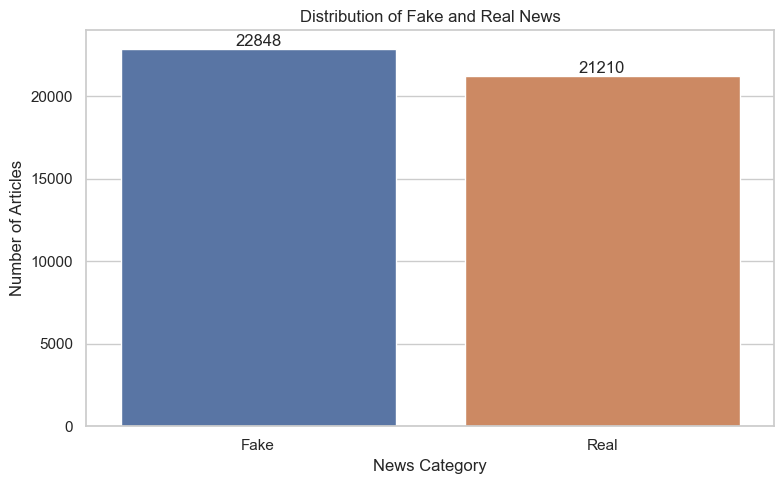

In [8]:
plt.figure(figsize=(8, 5))

class_counts = news_data["label"].value_counts()

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribution of Fake and Real News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()

plt.savefig(
    "plot1_news_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

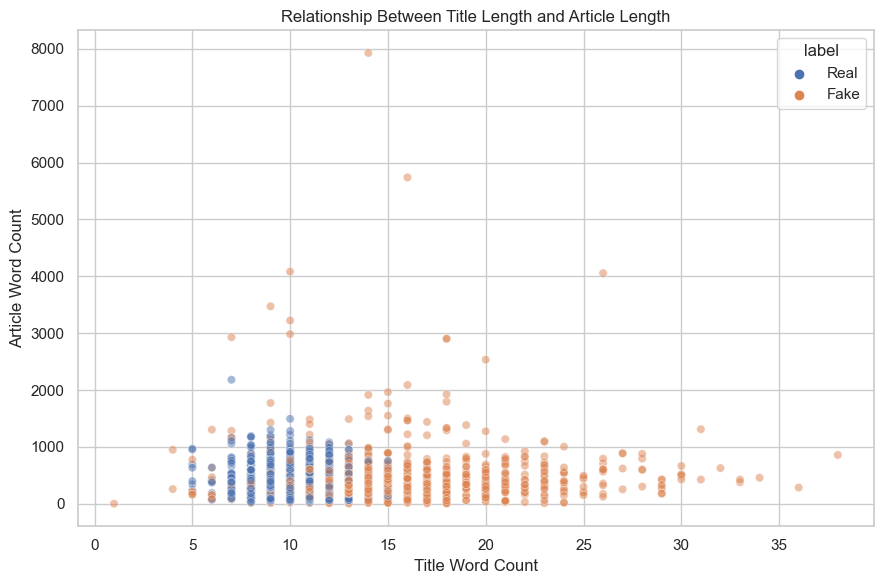

Pearson correlation:
                  title_word_count  word_count
title_word_count           1.00000     0.05721
word_count                 0.05721     1.00000

Correlation by category:
                        title_word_count  word_count
label                                               
Fake  title_word_count          1.000000    0.033919
      word_count                0.033919    1.000000
Real  title_word_count          1.000000   -0.038348
      word_count               -0.038348    1.000000


In [9]:
plt.figure(figsize=(9, 6))

# Sample data to make the scatter plot easier to read
plot_sample = news_data.sample(
    n=min(2500, len(news_data)),
    random_state=42
)

sns.scatterplot(
    data=plot_sample,
    x="title_word_count",
    y="word_count",
    hue="label",
    alpha=0.5
)

plt.title("Relationship Between Title Length and Article Length")
plt.xlabel("Title Word Count")
plt.ylabel("Article Word Count")

plt.tight_layout()

plt.savefig(
    "plot2_title_article_relationship.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Calculate correlation
print("Pearson correlation:")
print(
    news_data[
        ["title_word_count", "word_count"]
    ].corr()
)

print("\nCorrelation by category:")
print(
    news_data.groupby("label")[
        ["title_word_count", "word_count"]
    ].corr()
)

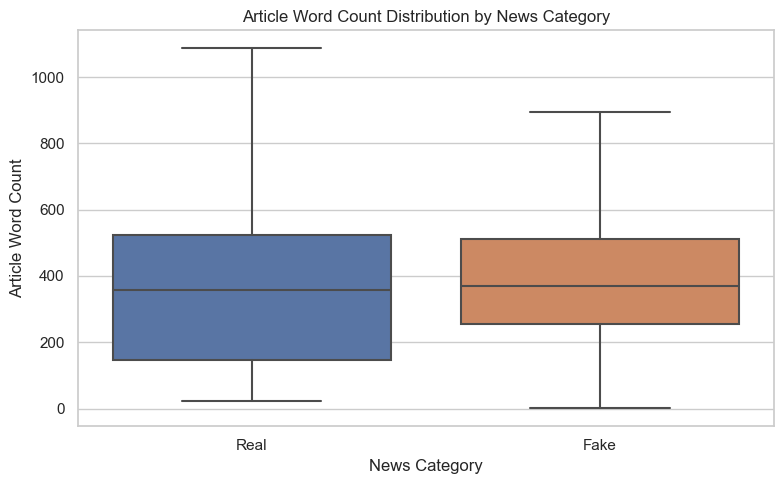

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=news_data,
    x="label",
    y="word_count",
    showfliers=False
)

plt.title("Article Word Count Distribution by News Category")
plt.xlabel("News Category")
plt.ylabel("Article Word Count")

plt.tight_layout()

plt.savefig(
    "plot3_article_length_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
print("MEDIAN ARTICLE LENGTH")

print(
    news_data.groupby("label")["word_count"].median()
)

print("\nMEAN ARTICLE LENGTH")

print(
    news_data.groupby("label")["word_count"].mean()
)

print("\nSTANDARD DEVIATION")

print(
    news_data.groupby("label")["word_count"].std()
)

print("\nQUARTILES")

print(
    news_data.groupby("label")["word_count"].quantile(
        [0.25, 0.50, 0.75]
    )
)

print("\nCorrelation between title and article length:")

print(
    news_data["title_word_count"].corr(
        news_data["word_count"]
    )
)

MEDIAN ARTICLE LENGTH
label
Fake    369.0
Real    359.0
Name: word_count, dtype: float64

MEAN ARTICLE LENGTH
label
Fake    434.893951
Real    384.775625
Name: word_count, dtype: float64

STANDARD DEVIATION
label
Fake    407.823671
Real    273.898818
Name: word_count, dtype: float64

QUARTILES
label      
Fake   0.25    254.0
       0.50    369.0
       0.75    511.0
Real   0.25    147.0
       0.50    359.0
       0.75    523.0
Name: word_count, dtype: float64

Correlation between title and article length:
0.057210232347259214


In [12]:
# Create numerical labels
news_data["class"] = news_data["label"].map({
    "Fake": 0,
    "Real": 1
})

# Text cleaning function
def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove text inside square brackets
    text = re.sub(r"\[.*?\]", "", text)

    # Remove punctuation
    text = re.sub(r"[%s]" % re.escape(string.punctuation), "", text)

    # Remove numbers
    text = re.sub(r"\d+", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


news_data["clean_text"] = news_data["text"].apply(clean_text)

print("Text cleaning completed!")

display(
    news_data[["text", "clean_text", "label"]].head()
)

Text cleaning completed!


,text,clean_text,label
0,WASHINGTON (Reuters) - The head of a conservat...,washington reuters the head of a conservative ...,Real
1,WASHINGTON (Reuters) - Transgender people will...,washington reuters transgender people will be ...,Real
2,WASHINGTON (Reuters) - The special counsel inv...,washington reuters the special counsel investi...,Real
3,WASHINGTON (Reuters) - Trump campaign adviser ...,washington reuters trump campaign adviser geor...,Real
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,seattlewashington reuters president donald tru...,Real


In [13]:
X = news_data["clean_text"]
y = news_data["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 33043
Testing records: 11015


In [14]:
vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF vectorisation completed!")

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

TF-IDF vectorisation completed!
Training matrix: (33043, 30000)
Testing matrix: (11015, 30000)


In [15]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [16]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("MODEL PERFORMANCE")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Fake", "Real"]
    )
)

MODEL PERFORMANCE
Accuracy: 98.84 %
Precision: 98.5 %
Recall: 99.09 %
F1 Score: 98.8 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fake       0.99      0.99      0.99      5712
        Real       0.99      0.99      0.99      5303

    accuracy                           0.99     11015
   macro avg       0.99      0.99      0.99     11015
weighted avg       0.99      0.99      0.99     11015



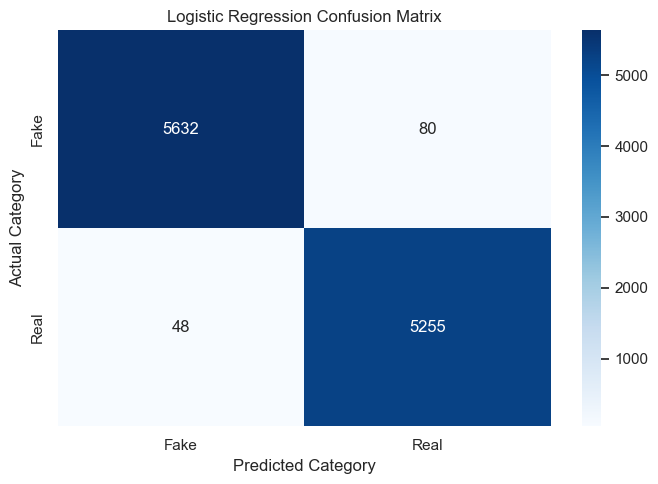

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()

plt.savefig(
    "plot4_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
performance = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(performance)

performance.to_csv(
    "model_performance.csv",
    index=False
)

print("Model performance saved successfully!")

,Metric,Score
0,Accuracy,0.988379
1,Precision,0.985005
2,Recall,0.990949
3,F1 Score,0.987968


Model performance saved successfully!


In [19]:
def predict_news(article):

    cleaned_article = clean_text(article)

    article_vector = vectorizer.transform(
        [cleaned_article]
    )

    prediction = model.predict(article_vector)[0]

    probability = model.predict_proba(article_vector)[0]

    if prediction == 1:
        result = "REAL NEWS"
        confidence = probability[1] * 100
    else:
        result = "FAKE NEWS"
        confidence = probability[0] * 100

    print("\nPrediction:", result)
    print("Model confidence:", round(confidence, 2), "%")

    return result


# Enter your own article
sample_article = input("Enter a news article: ")

predict_news(sample_article)

Enter a news article: Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a great year for America! As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year. 2018 will be a great year for America!  Donald J. Trump (@realDonaldTrump) December 31, 2017Trump s tweet went down about as welll as you d expect.What kind of president sends a New Year s greeting like this despicable, petty, infantile gibberish? Only Trump! His lac

'FAKE NEWS'

In [20]:
# Save cleaned dataset
news_data.to_csv(
    "cleaned_news_dataset.csv",
    index=False
)

# Save class distribution
class_distribution = news_data["label"].value_counts()

class_distribution.to_csv(
    "class_distribution.csv"
)

print("ALL OUTPUTS SAVED SUCCESSFULLY!")

print("\nGenerated files:")
print("1. statistical_summary.csv")
print("2. plot1_news_distribution.png")
print("3. plot2_title_article_relationship.png")
print("4. plot3_article_length_boxplot.png")
print("5. plot4_confusion_matrix.png")
print("6. model_performance.csv")
print("7. cleaned_news_dataset.csv")

ALL OUTPUTS SAVED SUCCESSFULLY!

Generated files:
1. statistical_summary.csv
2. plot1_news_distribution.png
3. plot2_title_article_relationship.png
4. plot3_article_length_boxplot.png
5. plot4_confusion_matrix.png
6. model_performance.csv
7. cleaned_news_dataset.csv


In [21]:
print("Confusion Matrix:")
print(cm)

print("\nTrue Negatives:", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives:", cm[1, 1])

Confusion Matrix:
[[5632   80]
 [  48 5255]]

True Negatives: 5632
False Positives: 80
False Negatives: 48
True Positives: 5255
